# Investigation 3: The Goal-to-Funding Reality

Compare funding goals and pledged amounts across all campaigns, then separately for successful and failed campaigns.

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Read the data from the project folder or this notebook's folder
data_path = Path("kickstarter.csv")
if not data_path.exists():
    data_path = Path("../../kickstarter.csv")

df = pd.read_csv(data_path, encoding="cp1252", low_memory=False)
df.columns = df.columns.str.strip()

# Keep the columns needed and remove unusable goal/pledged pairs
original_count = len(df)
df = df[["goal", "pledged", "state"]].copy()
for col in ["goal", "pledged"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["state"] = df["state"].str.strip()
df = df.dropna(subset=["goal", "pledged"])

print("Campaigns included:", len(df))
print("Rows removed:", original_count - len(df))
df.head()

Campaigns included: 323118
Rows removed: 632


,goal,pledged,state
0,1000.0,0.0,failed
1,45000.0,220.0,failed
2,5000.0,1.0,failed
3,19500.0,1283.0,canceled
4,50000.0,52375.0,successful


## Part A: All campaigns

Calculate sample covariance and Pearson correlation using the original `goal` and `pledged` values. Keep all outcomes and outliers.

In [2]:
# Calculate covariance and correlation across the entire usable dataset
covariance = df["goal"].cov(df["pledged"])
correlation = df["goal"].corr(df["pledged"])

print(f"Covariance: {covariance:,.2f}")
print(f"Correlation (r): {correlation:.4f}")

Covariance: 694,333,865.36
Correlation (r): 0.0068


## Part B: Successful and failed campaigns

Use the same calculation separately for each outcome.

In [3]:
# Separate successful campaigns from failed campaigns
successful = df[df["state"] == "successful"]
failed = df[df["state"] == "failed"]

successful_corr = successful["goal"].corr(successful["pledged"])
failed_corr = failed["goal"].corr(failed["pledged"])

print(f"Successful campaigns: {len(successful):,}; r = {successful_corr:.4f}")
print(f"Failed campaigns: {len(failed):,}; r = {failed_corr:.4f}")

Successful campaigns: 113,081; r = 0.5125
Failed campaigns: 168,221; r = 0.0227


## Visualizations

The axes use a symlog scale to show the large range of amounts while keeping zero pledges visible. All points are included; the calculations above use the original values, not log values. Amounts are in each campaign's original currency, so the pooled results mix currencies.

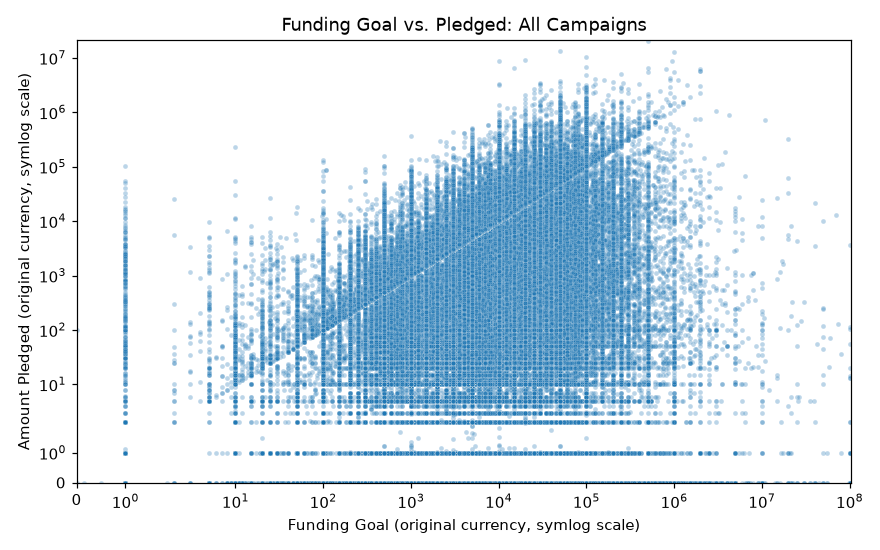

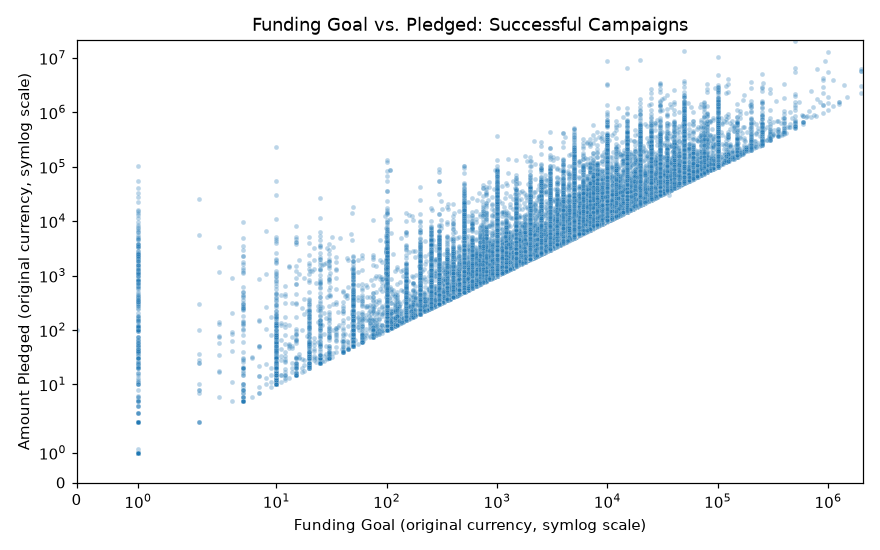

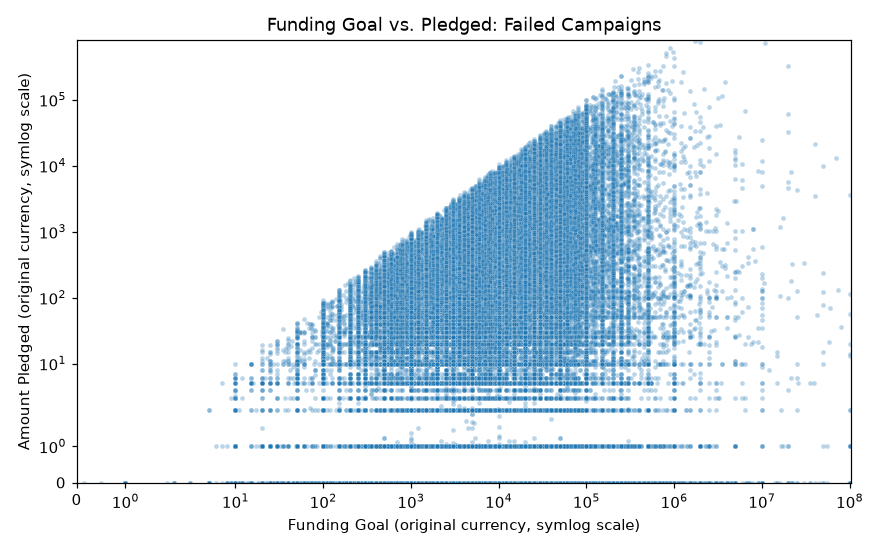

In [4]:
# Compare goals and pledges for all campaigns and each outcome
for title, data in [("All Campaigns", df), ("Successful Campaigns", successful),
                    ("Failed Campaigns", failed)]:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=data, x="goal", y="pledged", alpha=0.3, s=10)
    plt.xscale("symlog")
    plt.yscale("symlog")
    plt.xlim(left=0)
    plt.ylim(bottom=0)
    plt.title("Funding Goal vs. Pledged: " + title)
    plt.xlabel("Funding Goal (original currency, symlog scale)")
    plt.ylabel("Amount Pledged (original currency, symlog scale)")
    plt.tight_layout()
    plt.show()